# 1 · Ingesta, unión y calidad de datos

Dos fuentes públicas, sin clave:

| Fuente | Qué aporta | Formato |
|---|---|---|
| **Banco Mundial** (API v2) | PIB real PPA, PIB per cápita, población, urbanización, industria, renovables, electricidad, pobreza, bosques | JSON por indicador |
| **Our World in Data** (Global Carbon Project) | CO2 territorial, de consumo, por combustible, uso del suelo, energía primaria, GEI totales | CSV de ~14 MB |

Pasos: **descarga con caché → lectura → validación de códigos ISO → unión 1 a 1 → agregado regional → cobertura (años faltantes)**.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display
from desarrollo_co2 import config, descarga, limpieza, union, desacople as D, kaya, kuznets as K, graficos
from desarrollo_co2.graficos import num   # formato español: 1.234,56

pd.set_option("display.float_format", lambda v: num(v, 2))
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

## 1.1 Descarga con caché

Si el archivo ya está en `data/raw/` no se vuelve a pedir a la API (los segundos lo muestran).

In [2]:
pd.DataFrame(descarga.descargar_todo())

,fuente,archivo,kb,modificado,segundos
0,Banco Mundial NY.GDP.MKTP.PP.KD,bm_NY.GDP.MKTP.PP.KD.json,"174,10",2026-10-20 04:12,"0,00"
1,Banco Mundial NY.GDP.PCAP.PP.KD,bm_NY.GDP.PCAP.PP.KD.json,"181,60",2026-10-20 04:12,"0,00"
2,Banco Mundial SP.POP.TOTL,bm_SP.POP.TOTL.json,"149,50",2026-10-20 04:12,"0,00"
3,Banco Mundial SP.URB.TOTL.IN.ZS,bm_SP.URB.TOTL.IN.ZS.json,"174,90",2026-10-20 04:12,"0,00"
4,Banco Mundial NV.IND.TOTL.ZS,bm_NV.IND.TOTL.ZS.json,"184,00",2026-10-20 04:12,"0,00"
5,Banco Mundial EG.FEC.RNEW.ZS,bm_EG.FEC.RNEW.ZS.json,"182,40",2026-10-20 04:12,"0,00"
6,Banco Mundial EG.ELC.ACCS.ZS,bm_EG.ELC.ACCS.ZS.json,"165,10",2026-10-20 04:12,"0,00"
7,Banco Mundial SI.POV.DDAY,bm_SI.POV.DDAY.json,"180,80",2026-10-20 04:12,"0,00"
8,Banco Mundial AG.LND.FRST.ZS,bm_AG.LND.FRST.ZS.json,"164,50",2026-10-20 04:12,"0,00"
9,Our World in Data CO2,owid-co2-data.csv,"14.041,00",2026-10-20 04:12,"0,00"


## 1.2 Lectura de cada fuente

In [3]:
bm = limpieza.leer_banco_mundial()
owid = limpieza.leer_owid()
print(f"Banco Mundial: {bm.shape}  ·  OWID: {owid.shape}")
bm.query("iso3 == 'ECU'").tail(3)

Banco Mundial: (700, 11)  ·  OWID: (700, 15)


,iso3,anio,pib_ppa,pib_pc_ppa,poblacion_bm,urbana_pct,industria_pct_pib,renovable_pct_consumo,acceso_electricidad_pct,pobreza_extrema_pct,bosque_pct
312,ECU,2022,"252.861.189.718,14","14.186,64","17.823.897,00","63,09","29,58",NaN,"100,00","4,40","49,93"
313,ECU,2023,"257.495.732.292,19","14.321,16","17.980.083,00","63,13","27,71",NaN,"98,70","4,70","49,81"
314,ECU,2024,"252.489.782.930,73","13.922,42","18.135.478,00","63,24","26,68",NaN,"98,50","7,30","49,69"


## 1.3 ¿Por qué unir por ISO3 y no por nombre?

Los nombres no coinciden entre fuentes (y no siempre están en español). El código ISO 3166-1 alfa-3 es el mismo en ambas.

In [4]:
import json
crudo = json.loads((config.CRUDOS / "bm_SP.POP.TOTL.json").read_text(encoding="utf-8"))
nombres_bm = {r["countryiso3code"]: r["country"]["value"] for r in crudo}
nombres_owid = (pd.read_csv(config.CRUDOS / "owid-co2-data.csv", usecols=["iso_code", "country"])
                .drop_duplicates().set_index("iso_code")["country"])
comp = pd.DataFrame({"Banco Mundial": nombres_bm}).join(nombres_owid.rename("OWID"))
comp["español (proyecto)"] = comp.index.map(config.PAISES)
comp[comp["Banco Mundial"] != comp["OWID"]]

,Banco Mundial,OWID,español (proyecto)
VEN,"Venezuela, RB",Venezuela,Venezuela


In [5]:
pd.DataFrame([limpieza.validar_paises(bm, "Banco Mundial"), limpieza.validar_paises(owid, "OWID")])

,fuente,faltan,sobran,ok
0,Banco Mundial,[],[],True
1,OWID,[],[],True


## 1.4 Unión 1 a 1

`validate="one_to_one"` hace fallar la unión si alguna fuente trae un país-año repetido; `indicator` dice de dónde vino cada fila.

In [6]:
unido = union.unir(bm, owid)
unido["origen"].value_counts()

origen
ambas        700
solo_bm        0
solo_owid      0
Name: count, dtype: int64

**Control cruzado de población**: OWID toma la población de la ONU y el Banco Mundial la suya. Si difieren, las cifras per cápita dependerían de la fuente elegida.

In [7]:
union.diferencia_poblacion(unido).head()

,iso3,pais,media,max_abs
0,ARG,Argentina,"-0,00","0,00"
1,BOL,Bolivia,"0,00","0,00"
2,BRA,Brasil,"-0,00","0,00"
3,CHL,Chile,"-0,00","0,00"
4,COL,Colombia,"0,00","0,00"


La diferencia máxima es 0,0 %: la serie de población es la misma en ambas fuentes, así que da igual cuál se use para calcular los valores per cápita.

## 1.5 Agregado regional

La región se construye **sumando** países (no promediando tasas). Solo entran los países con PIB, CO2 y población en todos los años; si en un año falta un miembro, el total queda vacío en lugar de bajar artificialmente.

In [8]:
panel, informe = union.construir_panel()
print("Miembros:", ", ".join(informe["miembros_region"]))
print("Excluidos:", ", ".join(f"{i} ({config.PAISES[i]})" for i in informe["excluidos_region"]))
print("Filas del panel:", len(panel))

Miembros: ARG, BOL, BRA, CHL, COL, CRI, DOM, ECU, GTM, HND, HTI, MEX, NIC, PAN, PER, PRY, SLV, URY
Excluidos: CUB (Cuba), VEN (Venezuela)
Filas del panel: 735


## 1.6 Cobertura y años faltantes

No se imputa ningún valor. Esta tabla documenta qué falta y cada análisis decide qué hacer.

In [9]:
from desarrollo_co2.pipeline import VARIABLES_COBERTURA
cob = limpieza.cobertura(panel[panel["iso3"] != config.REGION], VARIABLES_COBERTURA)
limpieza.resumen_cobertura(cob)

estado,completo,parcial,sin datos,pct_medio
variable,,,,
acceso_electricidad_pct,5,15,0,"92,00"
bosque_pct,19,1,0,"99,90"
co2_con_luc_mt,20,0,0,"100,00"
co2_consumo_mt,0,18,2,"87,00"
co2_mt,20,0,0,"100,00"
energia_twh,20,0,0,"100,00"
gei_total_mt,20,0,0,"100,00"
industria_pct_pib,17,3,0,"97,40"
pib_pc_ppa,18,0,2,"90,00"


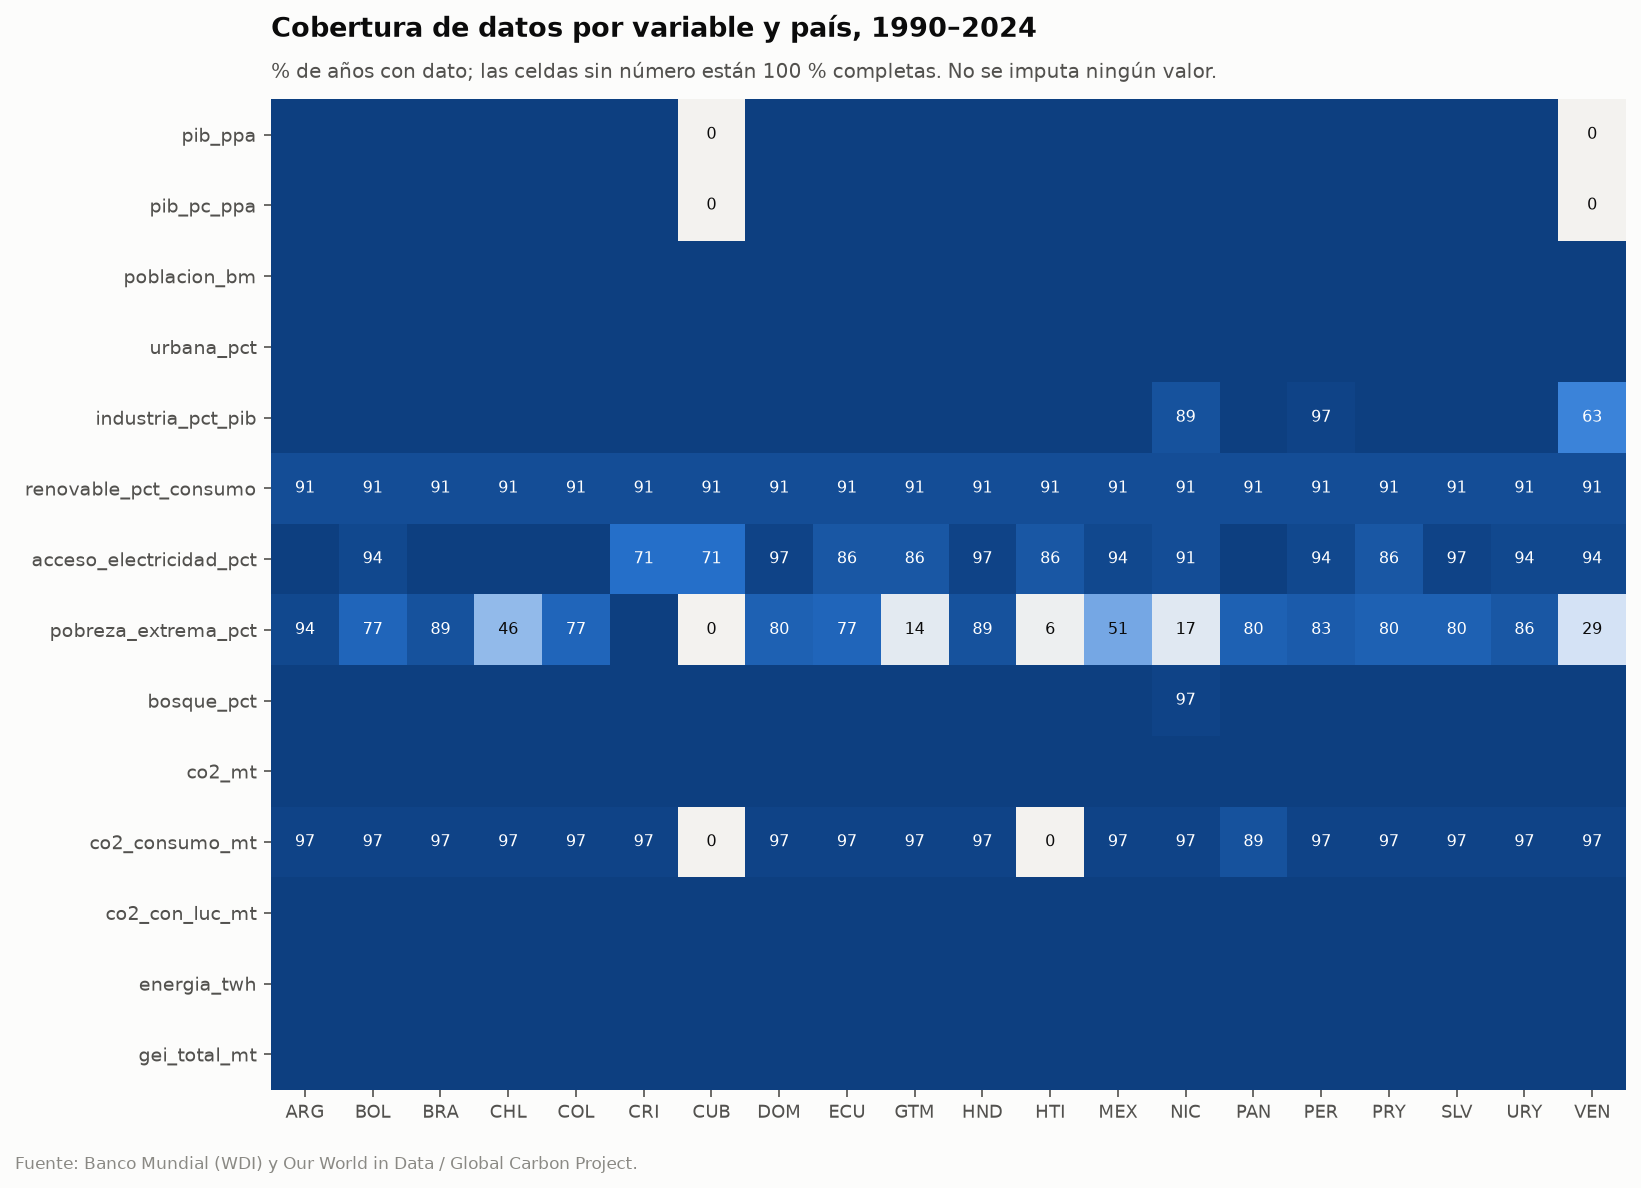

In [10]:
display(Image(config.FIGURAS / "01_cobertura.png"))

Detalle de los huecos que afectan al análisis:

In [11]:
claves = ["pib_ppa", "co2_consumo_mt", "renovable_pct_consumo", "pobreza_extrema_pct"]
(cob[cob["variable"].isin(claves) & (cob["pct_completo"] < 100)]
 .sort_values(["variable", "pct_completo"])[["variable", "iso3", "pct_completo", "anios_faltantes"]]
 .head(25))

,variable,iso3,pct_completo,anios_faltantes
206,co2_consumo_mt,CUB,"0,00",1990–2024
211,co2_consumo_mt,HTI,"0,00",1990–2024
214,co2_consumo_mt,PAN,"88,60","2006, 2008, 2016, 2024"
200,co2_consumo_mt,ARG,"97,10",2024
201,co2_consumo_mt,BOL,"97,10",2024
202,co2_consumo_mt,BRA,"97,10",2024
203,co2_consumo_mt,CHL,"97,10",2024
204,co2_consumo_mt,COL,"97,10",2024
205,co2_consumo_mt,CRI,"97,10",2024
207,co2_consumo_mt,DOM,"97,10",2024


**Qué implica cada hueco:**

* **PIB de Cuba y Venezuela**: el Banco Mundial no publica PIB en PPA para ellos. Quedan fuera del desacople, de Kaya y de Kuznets (aparecen solo en las gráficas de emisiones). Venezuela es el caso que más se pierde: su CO2 cayó ~21 % por el colapso económico, que no es desacople.
* **CO2 de consumo**: llega hasta 2023 y falta para Cuba y Haití; por eso la prueba de robustez usa 2000–2023.
* **Renovables (% del consumo)**: termina en 2021.
* **CO2 por combustible**: OWID deja vacío el gas o el carbón de los países que no los usan. Es la única excepción a "no imputar": se pone 0 solo cuando los combustibles con dato ya suman el total (±2 %), porque entonces el vacío es lógicamente un cero (`limpieza.completar_combustibles`).
* **Pobreza extrema**: es una serie de encuestas con huecos grandes (Guatemala, Haití y Nicaragua tienen menos del 20 % de los años), así que no sirve como variable de control en una regresión de panel.

## 1.7 Un dato raro en la fuente: Ecuador 1994

In [12]:
panel.query("iso3 == 'ECU' and 1992 <= anio <= 1997")[["anio", "co2_mt", "co2_petroleo_mt", "energia_twh", "pib_ppa"]]

,anio,co2_mt,co2_petroleo_mt,energia_twh,pib_ppa
282,1992,"22,00","19,14","88,98","101.555.874.853,46"
283,1993,"24,12","21,12","92,23","103.559.793.795,04"
284,1994,"14,34","10,65","100,32","107.969.629.156,95"
285,1995,"23,53","19,56","94,82","110.401.697.583,36"
286,1996,"25,34","20,86","107,91","112.313.576.360,41"
287,1997,"19,46","15,25","120,22","117.174.356.049,80"


El CO2 de Ecuador cae a la mitad en 1994 y se recupera en 1995 sin que el PIB o la energía cambien igual. Es un artefacto de la serie de combustibles líquidos de la fuente, no un hecho económico. No lo corrijo (sería inventar un dato), pero **el análisis de desacople empieza en 2000 y usa promedios de 3 años**, así que no le afecta.

In [13]:
panel.to_csv(config.PANEL, index=False)
cob.to_csv(config.COBERTURA, index=False)
f"Panel guardado: {config.PANEL.relative_to(config.RAIZ)} ({config.PANEL.stat().st_size / 1024:.0f} KB)"

'Panel guardado: data\\procesados\\panel_latam.csv (248 KB)'